# Практикум. Повнозв’язні нейронні мережі

**Виконав:** Брагнюк Андрій Романович  
**Група:** 4-8  
**Дата:** 24.11.2026

**Мета:** розглянути роботу нейрона, навчити мережу розпізнавати цифри
та перевірити вплив Dropout на результат.

## Підготовка

Підключаю бібліотеки та фіксую seed. Комірки виконуються зверху вниз.
Набір digits входить до scikit-learn.
Якщо бібліотек немає, їх можна встановити командою
`%pip install tensorflow numpy pandas matplotlib scikit-learn pydot`.
Для необов’язкової схеми архітектури також потрібен Graphviz.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

keras.utils.set_random_seed(42)

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__ if hasattr(keras, "__version__") else "tf.keras")
print("NumPy:", np.__version__)

TensorFlow: 2.21.0
Keras: 3.15.1
NumPy: 2.3.5


## 1. Штучний нейрон

Обчислюю зважену суму входів і додаю зсув: `z = x · w + b`.
Потім застосовую ReLU, яка залишає додатне значення, а від’ємне замінює нулем.

In [2]:
x = np.array([2.0, 1.0])
w = np.array([0.5, -1.0])
b = 0.2

z = np.dot(x, w) + b
activation = np.maximum(0.0, z)  # ReLU(z) = max(0, z)

print(f"Зважена сума: z = {z:.2f}")
print(f"Вихід нейрона: a = {activation:.2f}")
assert np.isclose(z, 0.2)

Зважена сума: z = 0.20
Вихід нейрона: a = 0.20


## 2. Функції активації

Будую графіки ReLU, sigmoid і tanh. ReLU використовую в прихованих шарах,
а softmax — на виході для 10 взаємовиключних класів.
Сума оцінок softmax дорівнює одиниці.

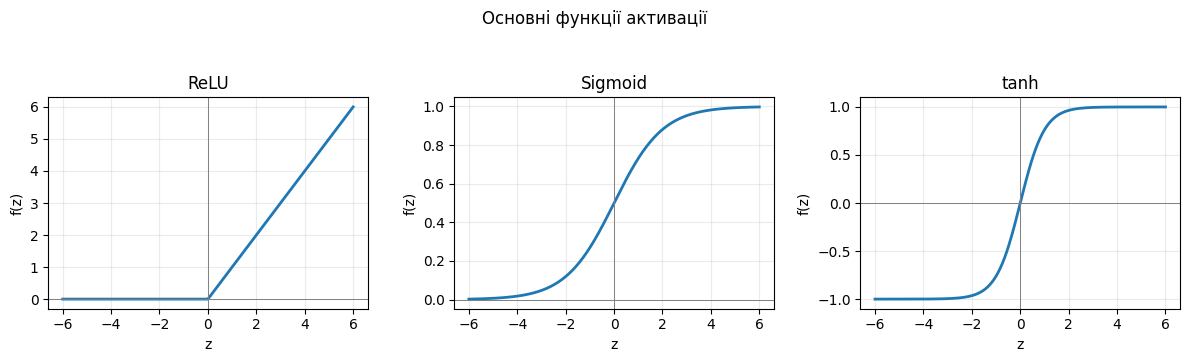

In [3]:
z_values = np.linspace(-6, 6, 400)
activation_functions = {
    "ReLU": np.maximum(0, z_values),
    "Sigmoid": 1 / (1 + np.exp(-z_values)),
    "tanh": np.tanh(z_values),
}

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, (name, values) in zip(axes, activation_functions.items()):
    ax.plot(z_values, values, linewidth=2)
    ax.axhline(0, color="gray", linewidth=0.7)
    ax.axvline(0, color="gray", linewidth=0.7)
    ax.set_title(name)
    ax.set_xlabel("z")
    ax.set_ylabel("f(z)")
    ax.grid(alpha=0.25)
plt.suptitle("Основні функції активації", y=1.05)
plt.tight_layout()
plt.show()

## 3. Набір даних

Завантажую digits: 1797 зображень розміром 8 × 8, класи — цифри від 0 до 9.
Перевіряю форми масивів, діапазон пікселів та перші 12 зображень.

Форма масиву зображень: (1797, 8, 8)
Форма масиву міток: (1797,)
Класи: [0 1 2 3 4 5 6 7 8 9]
Діапазон пікселів: 0.0 — 16.0


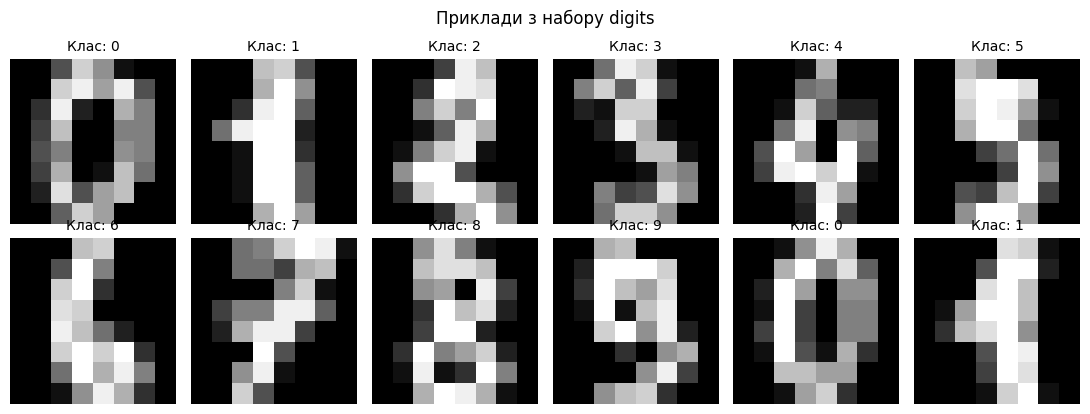

In [4]:
digits = load_digits()
images = digits.images
labels = digits.target

print("Форма масиву зображень:", images.shape)
print("Форма масиву міток:", labels.shape)
print("Класи:", np.unique(labels))
print("Діапазон пікселів:", images.min(), "—", images.max())

fig, axes = plt.subplots(2, 6, figsize=(11, 4.2))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i], cmap="gray", vmin=0, vmax=16)
    ax.set_title(f"Клас: {labels[i]}", fontsize=10)
    ax.axis("off")
plt.suptitle("Приклади з набору digits")
plt.tight_layout()
plt.show()

### Нормалізація та поділ

Ділю пікселі на 16, отримую значення від 0 до 1.
Відділяю 20% даних для тестування, а решту ділю на навчальну й валідаційну частини.
Stratify зберігає приблизне співвідношення класів.

In [5]:
x_all = images.astype("float32") / 16.0
y_all = labels.astype("int64")

# 80% даних — для навчання + валідації; 20% — тест
x_trainval, x_test, y_trainval, y_test = train_test_split(
    x_all, y_all, test_size=0.20, random_state=42, stratify=y_all
)

# Із trainval виділяємо 20% для валідації
x_train, x_val, y_train, y_val = train_test_split(
    x_trainval, y_trainval, test_size=0.20,
    random_state=42, stratify=y_trainval
)

for name, x_part, y_part in [
    ("Навчальна", x_train, y_train),
    ("Валідаційна", x_val, y_val),
    ("Тестова", x_test, y_test),
]:
    print(f"{name:12s}: x={x_part.shape}, y={y_part.shape}")

assert np.all((x_train >= 0) & (x_train <= 1))
assert x_train.shape[1:] == (8, 8)
assert len(np.unique(y_train)) == 10

Навчальна   : x=(1149, 8, 8), y=(1149,)
Валідаційна : x=(288, 8, 8), y=(288,)
Тестова     : x=(360, 8, 8), y=(360,)


## 4. Базова модель

Flatten перетворює зображення на 64 ознаки. Далі використовую Dense на 64 і 32 нейрони,
BatchNormalization, ReLU та Dropout 0,2. Вихідний шар має 10 нейронів із softmax.
Перед BatchNormalization вимикаю bias у Dense, оскільки нормалізація має власний зсув.

In [6]:
model = keras.Sequential([
    keras.Input(shape=(8, 8), name="image"),
    layers.Flatten(name="flatten"),
    layers.Dense(64, use_bias=False, name="dense_64"),
    layers.BatchNormalization(name="batch_norm"),
    layers.Activation("relu", name="relu"),
    layers.Dropout(0.20, name="dropout"),
    layers.Dense(32, activation="relu", name="dense_32"),
    layers.Dense(10, activation="softmax", name="classes"),
], name="digits_mlp")

model.summary()
print("Всього параметрів:", model.count_params())

Model: "digits_mlp"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_64 (Dense)                │ (None, 64)             │         4,096 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm (BatchNormalization) │ (None, 64)             │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu (Activation)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼─────────────────────

### Параметри та схема

Перший Dense має 4096 параметрів, другий — 2080, вихідний — 330.
BatchNormalization додає 256: 128 навчуваних і 128 ненавчуваних.
Разом — 6762 параметри. Додатково виводжу схему, якщо встановлено Graphviz і pydot.

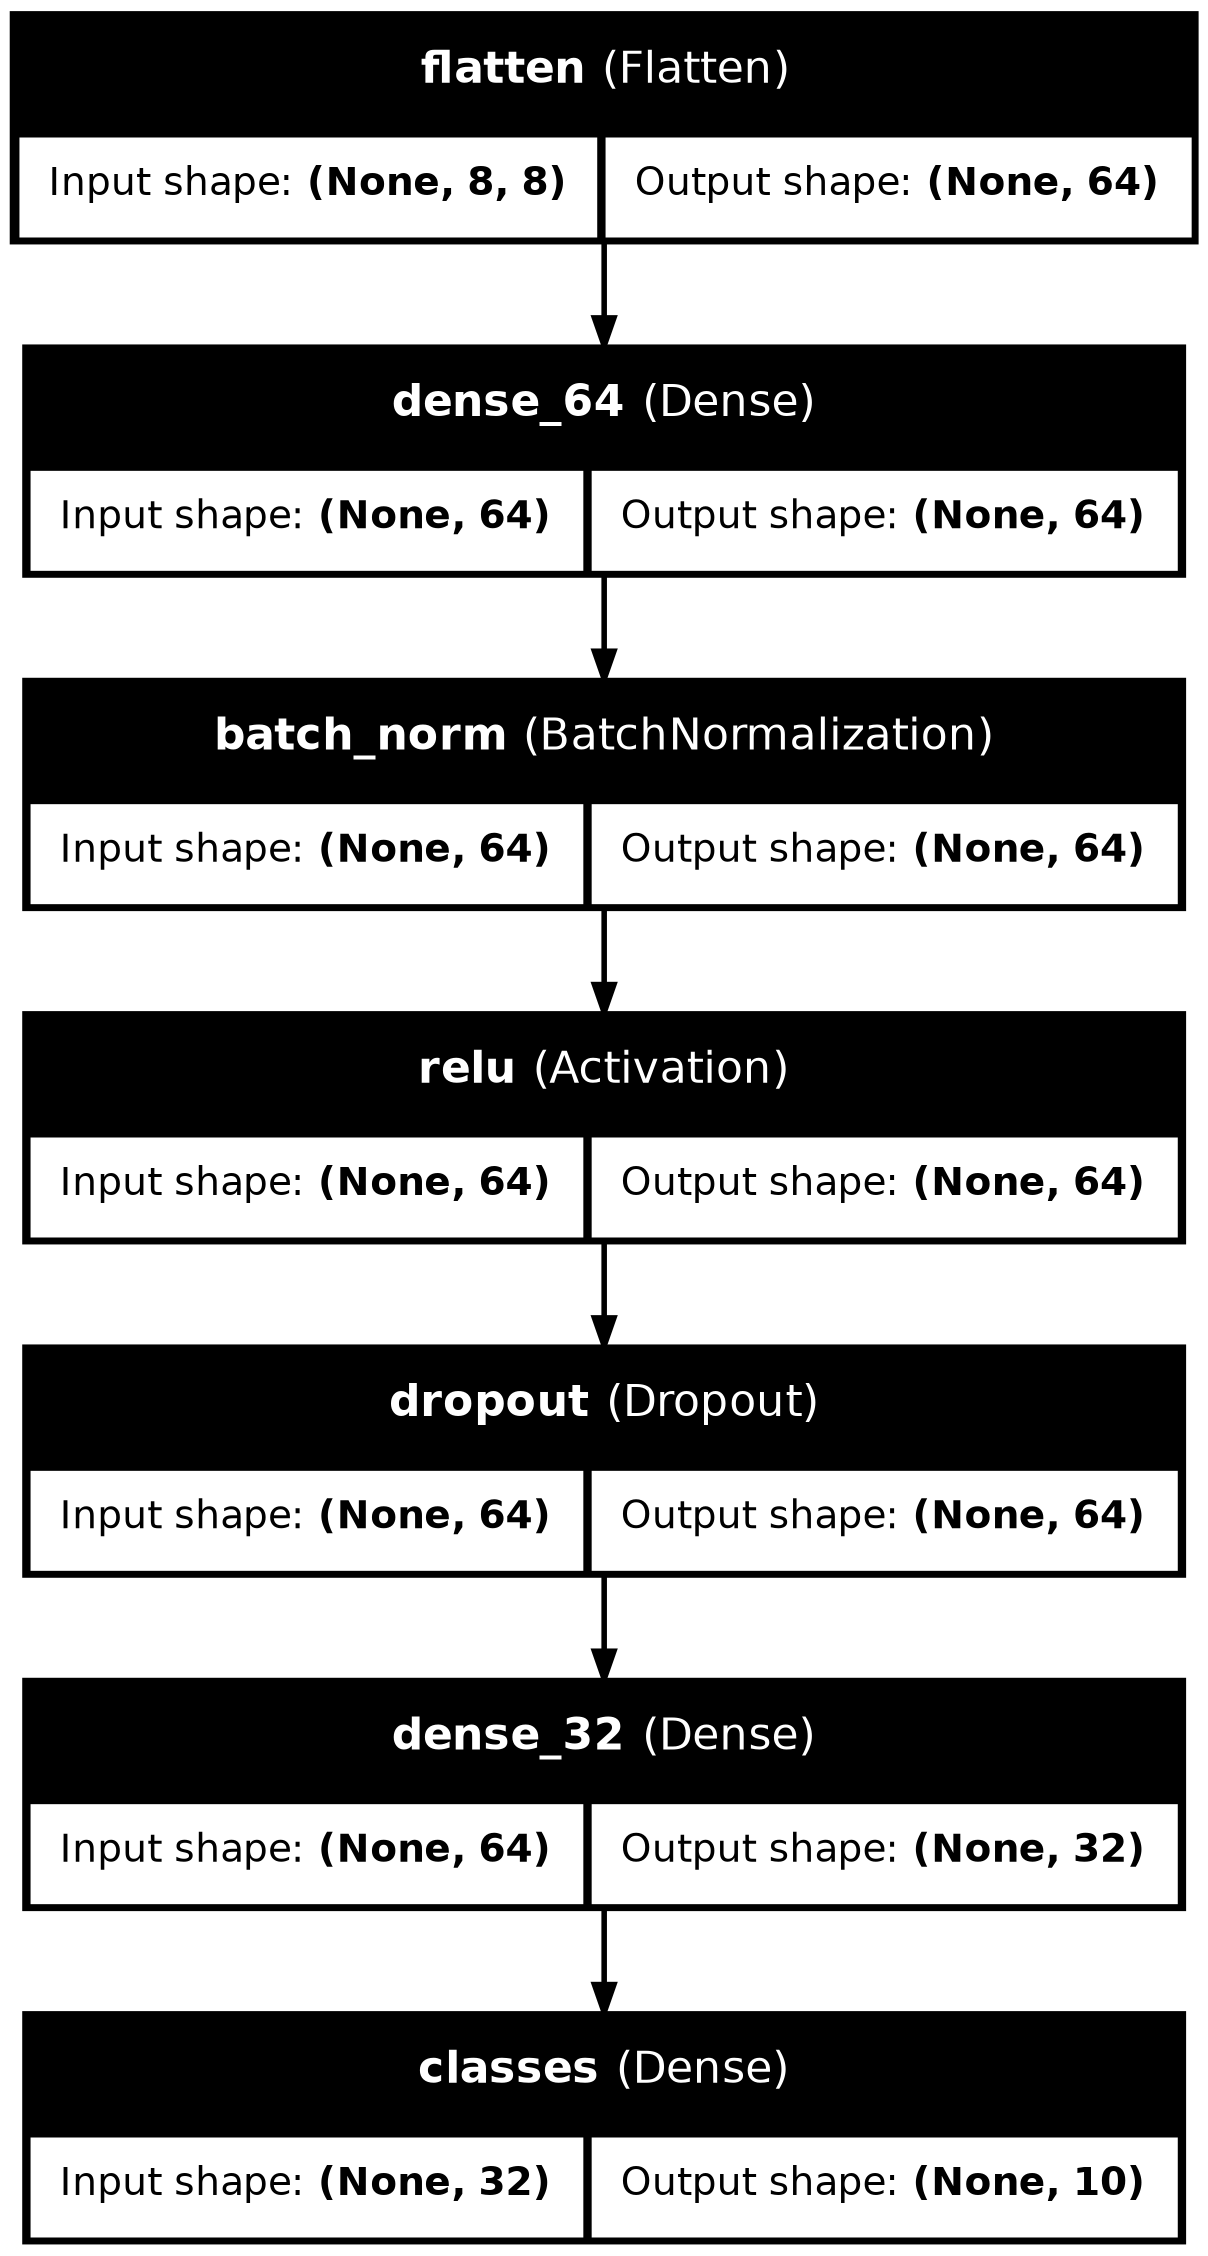

In [7]:
try:
    from IPython.display import Image, display

    keras.utils.plot_model(
        model,
        to_file="digits_mlp_architecture.png",
        show_shapes=True,
        show_layer_names=True,
        rankdir="TB",
    )
    display(Image(filename="digits_mlp_architecture.png"))
except Exception as exc:
    print("Графічна схема недоступна; скористайтеся model.summary().")
    print("Причина:", type(exc).__name__, str(exc)[:250])

## 5. Компіляція

Для базової моделі беру Adam із кроком 0,001.
Мітки задані цілими числами, тому використовую SparseCategoricalCrossentropy.
Accuracy показує частку правильно розпізнаних цифр.

In [8]:
# Приклади альтернатив (для ознайомлення):
sgd_optimizer = keras.optimizers.SGD(learning_rate=0.01, momentum=0.9)
adam_optimizer = keras.optimizers.Adam(learning_rate=0.001)

model.compile(
    optimizer=adam_optimizer,
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

print("Оптимізатор моделі:", type(model.optimizer).__name__)
print("Функція втрат: SparseCategoricalCrossentropy")

Оптимізатор моделі: Adam
Функція втрат: SparseCategoricalCrossentropy


## 6. Навчання

Навчаю до 30 епох пакетами по 32 зображення.
EarlyStopping стежить за val_loss і відновлює ваги з найменшими валідаційними втратами.

In [9]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
)

history = model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=30,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=2,
)

print("Фактична кількість епох:", len(history.history["loss"]))

Epoch 1/30
36/36 - 1s - 33ms/step - accuracy: 0.3238 - loss: 2.0187 - val_accuracy: 0.4340 - val_loss: 1.9900
Epoch 2/30
36/36 - 0s - 3ms/step - accuracy: 0.6675 - loss: 1.2706 - val_accuracy: 0.8229 - val_loss: 1.5783
Epoch 3/30
36/36 - 0s - 3ms/step - accuracy: 0.8242 - loss: 0.8112 - val_accuracy: 0.9271 - val_loss: 1.1033
Epoch 4/30
36/36 - 0s - 3ms/step - accuracy: 0.8764 - loss: 0.5418 - val_accuracy: 0.9444 - val_loss: 0.7300
Epoch 5/30
36/36 - 0s - 6ms/step - accuracy: 0.9060 - loss: 0.3932 - val_accuracy: 0.9618 - val_loss: 0.4812
Epoch 6/30
36/36 - 0s - 4ms/step - accuracy: 0.9286 - loss: 0.2999 - val_accuracy: 0.9653 - val_loss: 0.3308
Epoch 7/30
36/36 - 0s - 3ms/step - accuracy: 0.9391 - loss: 0.2414 - val_accuracy: 0.9722 - val_loss: 0.2367
Epoch 8/30
36/36 - 0s - 3ms/step - accuracy: 0.9530 - loss: 0.2011 - val_accuracy: 0.9688 - val_loss: 0.1863
Epoch 9/30
36/36 - 0s - 4ms/step - accuracy: 0.9460 - loss: 0.1826 - val_accuracy: 0.9757 - val_loss: 0.1486
Epoch 10/30
36/36 

## 7. Графіки навчання

Порівнюю loss і accuracy на навчальних та валідаційних даних.
Dropout працює лише під час навчання, а BatchNormalization змінює режим роботи,
тому валідаційна точність іноді може бути вищою за навчальну.

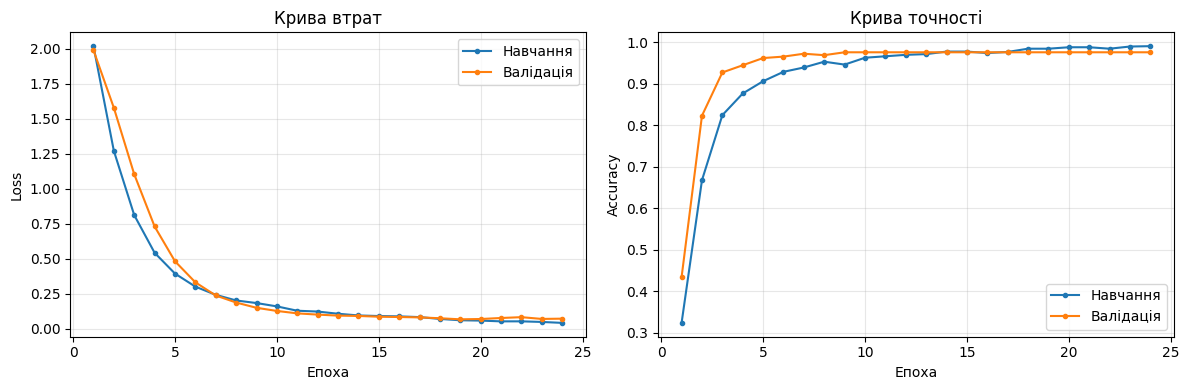

In [10]:
epochs_done = np.arange(1, len(history.history["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs_done, history.history["loss"], label="Навчання", marker="o", ms=3)
axes[0].plot(epochs_done, history.history["val_loss"], label="Валідація", marker="o", ms=3)
axes[0].set(title="Крива втрат", xlabel="Епоха", ylabel="Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs_done, history.history["accuracy"], label="Навчання", marker="o", ms=3)
axes[1].plot(epochs_done, history.history["val_accuracy"], label="Валідація", marker="o", ms=3)
axes[1].set(title="Крива точності", xlabel="Епоха", ylabel="Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 8. Тестування

Оцінюю навчену мережу на відкладених даних.
Із вектора softmax беру індекс найбільшого значення — це прогнозований клас.

In [11]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
probabilities = model.predict(x_test, verbose=0)
predicted_classes = np.argmax(probabilities, axis=1)
confidence = probabilities.max(axis=1)

print(f"Тестові втрати: {test_loss:.4f}")
print(f"Тестова точність: {test_accuracy:.2%}")
print(f"Правильно: {(predicted_classes == y_test).sum()} із {len(y_test)}")
print("Форма прогнозів:", probabilities.shape)
assert probabilities.shape == (len(x_test), 10)

Тестові втрати: 0.0679
Тестова точність: 97.78%
Правильно: 352 із 360
Форма прогнозів: (360, 10)


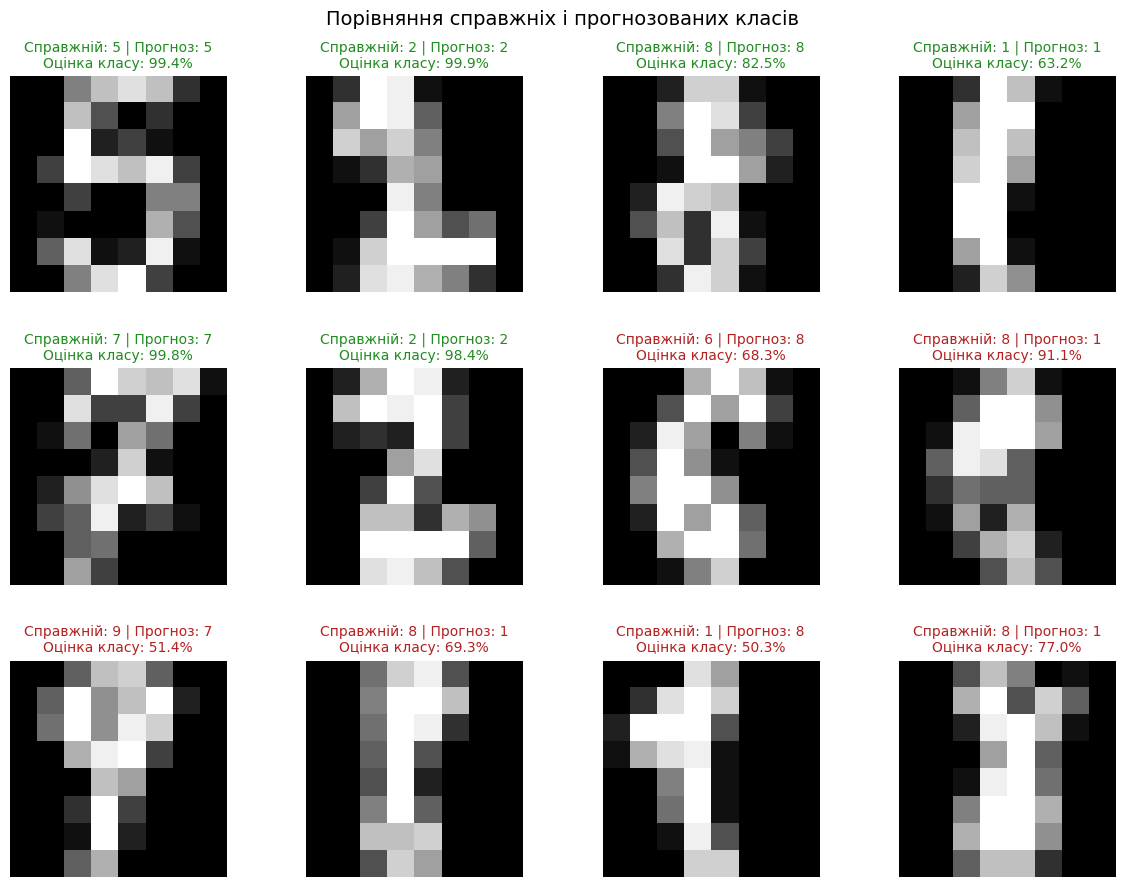

In [12]:
correct_idx = np.flatnonzero(predicted_classes == y_test)
wrong_idx = np.flatnonzero(predicted_classes != y_test)

# До 6 правильних і до 6 помилкових прикладів; решту місць доповнюємо правильними
selected = list(correct_idx[:6]) + list(wrong_idx[:6])
if len(selected) < 12:
    selected += list(correct_idx[6:6 + (12 - len(selected))])

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for ax, idx in zip(axes.flat, selected):
    is_correct = predicted_classes[idx] == y_test[idx]
    color = "forestgreen" if is_correct else "firebrick"
    ax.imshow(x_test[idx], cmap="gray", vmin=0, vmax=1)
    ax.set_title(
        f"Справжній: {y_test[idx]} | Прогноз: {predicted_classes[idx]}\n"
        f"Оцінка класу: {confidence[idx]:.1%}",
        color=color,
        fontsize=10,
    )
    ax.axis("off")
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_edgecolor(color)
        spine.set_linewidth(2)
for ax in axes.flat[len(selected):]:
    ax.axis("off")
plt.suptitle("Порівняння справжніх і прогнозованих класів", fontsize=14)
plt.tight_layout(h_pad=3.0)
plt.show()

### Матриця помилок

Виводжу precision, recall і F1-score. У матриці рядки відповідають справжнім класам,
а стовпці — прогнозованим.

              precision    recall  f1-score   support

           0      1.000     1.000     1.000        36
           1      0.921     0.972     0.946        36
           2      0.946     1.000     0.972        35
           3      1.000     1.000     1.000        37
           4      1.000     1.000     1.000        36
           5      1.000     1.000     1.000        37
           6      1.000     0.972     0.986        36
           7      0.973     1.000     0.986        36
           8      0.938     0.857     0.896        35
           9      1.000     0.972     0.986        36

    accuracy                          0.978       360
   macro avg      0.978     0.977     0.977       360
weighted avg      0.978     0.978     0.978       360



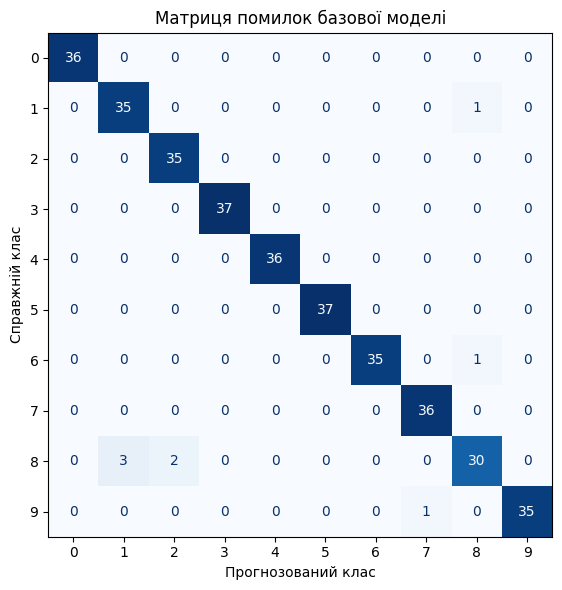

In [13]:
print(classification_report(y_test, predicted_classes, digits=3, zero_division=0))

matrix = confusion_matrix(y_test, predicted_classes, labels=np.arange(10))
display_matrix = ConfusionMatrixDisplay(confusion_matrix=matrix, display_labels=np.arange(10))
fig, ax = plt.subplots(figsize=(7, 6))
display_matrix.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.set_title("Матриця помилок базової моделі")
ax.set_xlabel("Прогнозований клас")
ax.set_ylabel("Справжній клас")
plt.tight_layout()
plt.show()

## 9. Збереження моделі

Зберігаю модель у файл .keras, завантажую її та порівнюю прогнози.
Для нових зображень потрібна така сама нормалізація — ділення на 16.

In [14]:
model.save("digits_mlp.keras")
restored_model = keras.models.load_model("digits_mlp.keras")

original_predictions = model.predict(x_test[:5], verbose=0)
restored_predictions = restored_model.predict(x_test[:5], verbose=0)
np.testing.assert_allclose(original_predictions, restored_predictions, atol=1e-6, rtol=1e-5)

print("Модель збережено до digits_mlp.keras і успішно відновлено.")

Модель збережено до digits_mlp.keras і успішно відновлено.


### Відповіді на контрольні запитання

1. **Flatten** перетворює масив 8 × 8 на вектор із 64 ознак для повнозв’язних шарів.
2. **Softmax** дає 10 невід’ємних оцінок із сумою 1; найбільша відповідає вибраному класу.
3. **Loss** оцінює помилку прогнозів і використовується для навчання, **accuracy** — частку правильних класів. **Val_loss** обчислюється на валідаційних даних без оновлення ваг.
4. Якщо підбирати архітектуру за тестовими результатами, тест перестане бути незалежною перевіркою.
5. **Кількість параметрів** — це ваги, зсуви та інші значення стану шарів; summary окремо показує навчувані й ненавчувані параметри.
6. Під час **fit** Dropout випадково зануляє частину активацій, а під час **predict** не застосовує це занулення.

# 10. Самостійне завдання

Створюю окрему модель на 128 і 64 нейрони з Dropout 0,30 та AdamW.
Для експерименту заздалегідь обираю одну зміну: Dropout 0,30 → 0,15.
Поділ даних, початкові ваги, оптимізатор, розмір пакета й умови зупинки залишаю однаковими.
Тестові результати використовую лише для підсумкового порівняння.

### Крок 1. Нова архітектура

Збільшую приховані шари до 128 і 64 нейронів. Базова model залишається окремо.
Зберігаю початкові ваги нової мережі для наступного експерименту.

In [15]:
keras.utils.set_random_seed(42)

student_model = keras.Sequential([
    keras.Input(shape=(8, 8)),
    layers.Flatten(),
    layers.Dense(128, use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.Dropout(0.30),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
], name="student_mlp")

initial_weights = student_model.get_weights()
student_model.summary()
print("Параметрів мережі:", student_model.count_params())

Model: "student_mlp"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │         8,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)        

### Крок 2. Компіляція та навчання

Обираю AdamW: він адаптує кроки оновлення й окремо зменшує ваги через weight decay.
Задаю learning_rate 0,001 і weight_decay 0,0001. Навчаю до 25 епох,
із тією самою валідаційною вибіркою та EarlyStopping.

In [16]:
student_model.compile(
    optimizer=keras.optimizers.AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

student_history = student_model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=25,
    batch_size=32,
    callbacks=[keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=5, restore_best_weights=True
    )],
    verbose=2
)

print("Виконано епох:", len(student_history.history["loss"]))

Epoch 1/25
36/36 - 1s - 36ms/step - accuracy: 0.5109 - loss: 1.6068 - val_accuracy: 0.8229 - val_loss: 1.7093
Epoch 2/25
36/36 - 0s - 4ms/step - accuracy: 0.8721 - loss: 0.6271 - val_accuracy: 0.8958 - val_loss: 1.1363
Epoch 3/25
36/36 - 0s - 4ms/step - accuracy: 0.9217 - loss: 0.3512 - val_accuracy: 0.9375 - val_loss: 0.7308
Epoch 4/25
36/36 - 0s - 4ms/step - accuracy: 0.9373 - loss: 0.2450 - val_accuracy: 0.9514 - val_loss: 0.4840
Epoch 5/25
36/36 - 0s - 4ms/step - accuracy: 0.9495 - loss: 0.1883 - val_accuracy: 0.9722 - val_loss: 0.3175
Epoch 6/25
36/36 - 0s - 4ms/step - accuracy: 0.9652 - loss: 0.1523 - val_accuracy: 0.9722 - val_loss: 0.2235
Epoch 7/25
36/36 - 0s - 3ms/step - accuracy: 0.9591 - loss: 0.1332 - val_accuracy: 0.9722 - val_loss: 0.1621
Epoch 8/25
36/36 - 0s - 4ms/step - accuracy: 0.9809 - loss: 0.0989 - val_accuracy: 0.9688 - val_loss: 0.1370
Epoch 9/25
36/36 - 0s - 4ms/step - accuracy: 0.9826 - loss: 0.0813 - val_accuracy: 0.9688 - val_loss: 0.1307
Epoch 10/25
36/36 

### Крок 3. Криві навчання

Будую графіки для нової мережі та порівнюю навчальні й валідаційні показники.

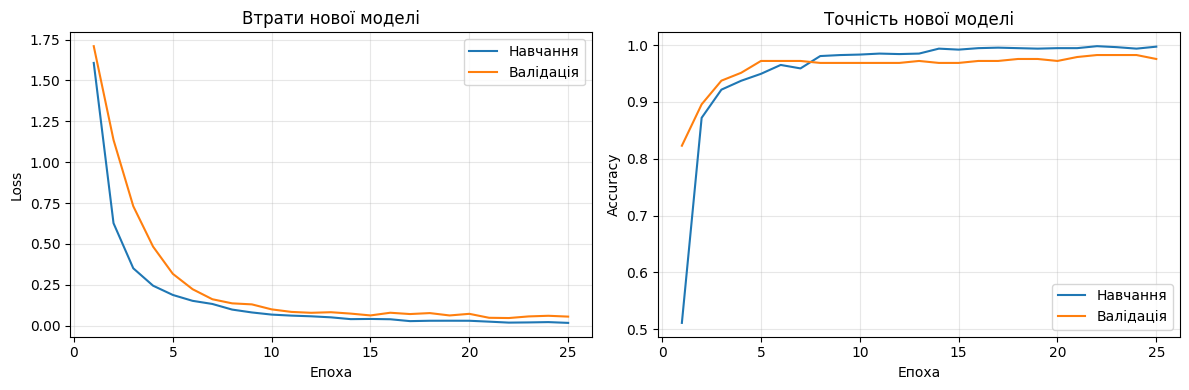

In [17]:
student_epochs = range(1, len(student_history.history["loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(student_epochs, student_history.history["loss"], label="Навчання")
axes[0].plot(student_epochs, student_history.history["val_loss"], label="Валідація")
axes[0].set(title="Втрати нової моделі", xlabel="Епоха", ylabel="Loss")

axes[1].plot(student_epochs, student_history.history["accuracy"], label="Навчання")
axes[1].plot(student_epochs, student_history.history["val_accuracy"], label="Валідація")
axes[1].set(title="Точність нової моделі", xlabel="Епоха", ylabel="Accuracy")

for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Найменший val_loss нової моделі — 0,0471 на 22-й епосі; наприкінці він зріс до 0,0559. На останній епосі навчальна точність дорівнює 99,74%, валідаційна — 97,57%. Недонавчання не спостерігається, але невеликий розрив і зростання val_loss свідчать про початок перенавчання.

### Крок 4. Тестові показники

Перевіряю student_model на тій самій тестовій вибірці.

Базова accuracy: 97.78%
Нова accuracy: 98.61%
Втрати нової моделі: 0.0493
Різниця: +0.83 в. п.
              precision    recall  f1-score   support

           0      1.000     1.000     1.000        36
           1      0.946     0.972     0.959        36
           2      1.000     1.000     1.000        35
           3      1.000     1.000     1.000        37
           4      1.000     1.000     1.000        36
           5      1.000     1.000     1.000        37
           6      0.972     0.972     0.972        36
           7      0.973     1.000     0.986        36
           8      0.971     0.943     0.957        35
           9      1.000     0.972     0.986        36

    accuracy                          0.986       360
   macro avg      0.986     0.986     0.986       360
weighted avg      0.986     0.986     0.986       360



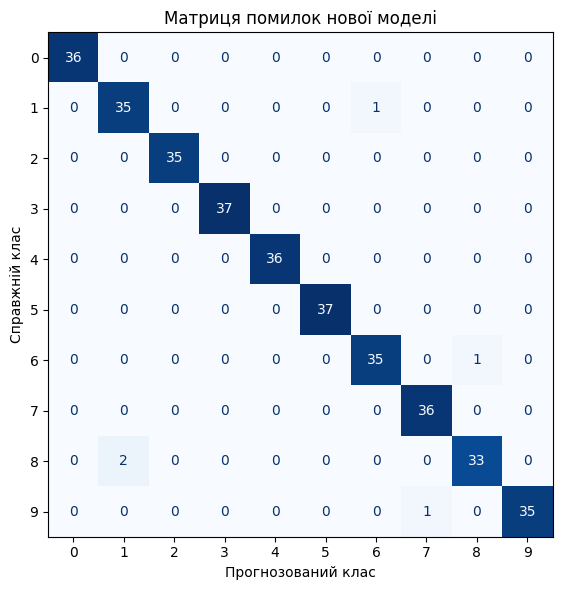

In [18]:
student_loss, student_accuracy = student_model.evaluate(x_test, y_test, verbose=0)
student_probabilities = student_model.predict(x_test, verbose=0)
student_predictions = np.argmax(student_probabilities, axis=1)

print(f"Базова accuracy: {test_accuracy:.2%}")
print(f"Нова accuracy: {student_accuracy:.2%}")
print(f"Втрати нової моделі: {student_loss:.4f}")
print(f"Різниця: {(student_accuracy - test_accuracy) * 100:+.2f} в. п.")
print(classification_report(y_test, student_predictions, digits=3, zero_division=0))

student_matrix = confusion_matrix(y_test, student_predictions, labels=np.arange(10))
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(student_matrix, display_labels=np.arange(10)).plot(
    ax=ax, cmap="Blues", colorbar=False, values_format="d"
)
ax.set(title="Матриця помилок нової моделі",
       xlabel="Прогнозований клас", ylabel="Справжній клас")
plt.tight_layout()
plt.show()

### Крок 5. Приклади прогнозів

Показую 12 зображень: правильні відповіді та помилки, якщо вони є.
Зеленим позначаю правильний прогноз, червоним — неправильний.

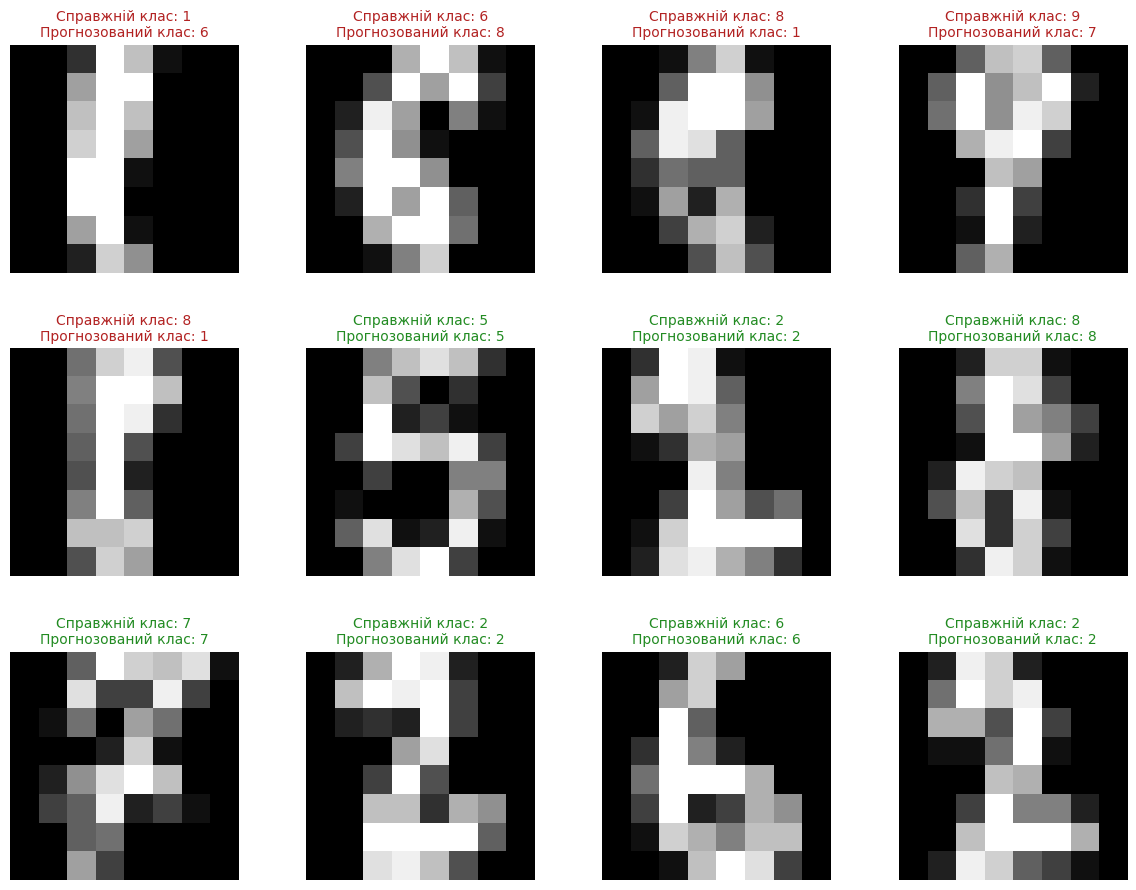

In [19]:
student_correct = np.flatnonzero(student_predictions == y_test)
student_wrong = np.flatnonzero(student_predictions != y_test)

selected = list(student_wrong[:6])
selected += list(student_correct[:12 - len(selected)])

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for ax, idx in zip(axes.flat, selected):
    color = "forestgreen" if student_predictions[idx] == y_test[idx] else "firebrick"
    ax.imshow(x_test[idx], cmap="gray", vmin=0, vmax=1)
    ax.set_title(
        f"Справжній клас: {y_test[idx]}\nПрогнозований клас: {student_predictions[idx]}",
        color=color, fontsize=10
    )
    ax.axis("off")

plt.tight_layout(h_pad=3.0)
plt.show()

### Крок 6. Зміна одного параметра

Зменшую тільки Dropout: 0,30 → 0,15. Створюю модель заново та задаю початкові ваги,
збережені до навчання student_model. Так порівняння не залежить від різної стартової
ініціалізації або додаткового навчання вже готової мережі.

In [20]:
keras.utils.set_random_seed(42)

experiment_model = keras.Sequential([
    keras.Input(shape=(8, 8)),
    layers.Flatten(),
    layers.Dense(128, use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.Dropout(0.15),  # Єдина зміна в налаштуваннях.
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
], name="experiment_mlp")
experiment_model.set_weights(initial_weights)

experiment_model.compile(
    optimizer=keras.optimizers.AdamW(learning_rate=0.001, weight_decay=0.0001),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

experiment_history = experiment_model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=25,
    batch_size=32,
    callbacks=[keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=5, restore_best_weights=True
    )],
    verbose=2
)

Epoch 1/25
36/36 - 1s - 31ms/step - accuracy: 0.5744 - loss: 1.5024 - val_accuracy: 0.8194 - val_loss: 1.6613
Epoch 2/25
36/36 - 0s - 4ms/step - accuracy: 0.9008 - loss: 0.5171 - val_accuracy: 0.8924 - val_loss: 1.0802
Epoch 3/25
36/36 - 0s - 3ms/step - accuracy: 0.9295 - loss: 0.2747 - val_accuracy: 0.9410 - val_loss: 0.6933
Epoch 4/25
36/36 - 0s - 4ms/step - accuracy: 0.9547 - loss: 0.1785 - val_accuracy: 0.9618 - val_loss: 0.4581
Epoch 5/25
36/36 - 0s - 4ms/step - accuracy: 0.9721 - loss: 0.1297 - val_accuracy: 0.9688 - val_loss: 0.3107
Epoch 6/25
36/36 - 0s - 4ms/step - accuracy: 0.9869 - loss: 0.0968 - val_accuracy: 0.9722 - val_loss: 0.2168
Epoch 7/25
36/36 - 0s - 3ms/step - accuracy: 0.9887 - loss: 0.0735 - val_accuracy: 0.9722 - val_loss: 0.1599
Epoch 8/25
36/36 - 0s - 4ms/step - accuracy: 0.9896 - loss: 0.0596 - val_accuracy: 0.9688 - val_loss: 0.1262
Epoch 9/25
36/36 - 0s - 4ms/step - accuracy: 0.9939 - loss: 0.0453 - val_accuracy: 0.9653 - val_loss: 0.1145
Epoch 10/25
36/36 

In [21]:
experiment_loss, experiment_accuracy = experiment_model.evaluate(x_test, y_test, verbose=0)
experiment_predictions = np.argmax(experiment_model.predict(x_test, verbose=0), axis=1)

print(f"Dropout 0.15: accuracy = {experiment_accuracy:.2%}, loss = {experiment_loss:.4f}")
print(f"Зміна accuracy: {(experiment_accuracy - student_accuracy) * 100:+.2f} в. п.")

comparison = pd.DataFrame({
    "Модель": ["Базова", "Нова", "Експеримент"],
    "Приховані нейрони": ["64, 32", "128, 64", "128, 64"],
    "Оптимізатор": ["Adam", "AdamW", "AdamW"],
    "Dropout": [0.20, 0.30, 0.15],
    "Епох": [len(history.history["loss"]), len(student_history.history["loss"]),
             len(experiment_history.history["loss"])],
    "Accuracy, %": [test_accuracy * 100, student_accuracy * 100, experiment_accuracy * 100],
    "Loss": [test_loss, student_loss, experiment_loss]
})
comparison.round({"Accuracy, %": 2, "Loss": 4})

Dropout 0.15: accuracy = 97.78%, loss = 0.0593
Зміна accuracy: -0.83 в. п.


,Модель,Приховані нейрони,Оптимізатор,Dropout,Епох,"Accuracy, %",Loss
0,Базова,"64, 32",Adam,0.20,24,97.78,0.0679
1,Нова,"128, 64",AdamW,0.30,25,98.61,0.0493
2,Експеримент,"128, 64",AdamW,0.15,25,97.78,0.0593


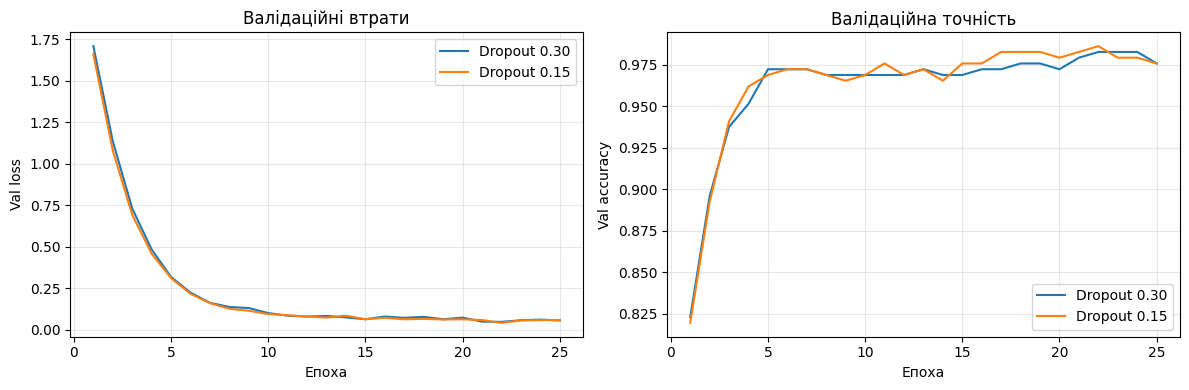

In [22]:
# Порівнюю валідаційні криві двох варіантів Dropout.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for hist, label in [(student_history, "Dropout 0.30"),
                    (experiment_history, "Dropout 0.15")]:
    epochs = range(1, len(hist.history["loss"]) + 1)
    axes[0].plot(epochs, hist.history["val_loss"], label=label)
    axes[1].plot(epochs, hist.history["val_accuracy"], label=label)

axes[0].set(title="Валідаційні втрати", xlabel="Епоха", ylabel="Val loss")
axes[1].set(title="Валідаційна точність", xlabel="Епоха", ylabel="Val accuracy")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [23]:
student_model.save("digits_student.keras")
experiment_model.save("digits_dropout_015.keras")
print("Збережено digits_student.keras та digits_dropout_015.keras")

Збережено digits_student.keras та digits_dropout_015.keras


### Висновок

Базова модель правильно розпізнала 352 із 360 зображень, її точність — 97,78%. Найкращий тестовий результат отримала нова мережа з AdamW і Dropout 0,30: 98,61%, тобто 355 правильних відповідей. На кривих нової моделі навчальні втрати продовжують зменшуватися, а валідаційні наприкінці трохи зростають, що вказує на невелике перенавчання. Найменші валідаційні втрати отримано на 22-й епосі, ваги якої відновив EarlyStopping. Найбільше помилок обидві моделі зробили для цифри 8: базова — 5, нова — 2; у новій моделі обидва ці зображення розпізнано як 1. Після зменшення Dropout до 0,15 точність становила 97,78%, що на 0,83 відсоткового пункту нижче за варіант 0,30. Отже, у цьому досліді менший Dropout не покращив тестовий результат, хоча за одним запуском не можна визначити найкраще значення для всіх випадків.

Джерела: наданий навчальний ноутбук; [документація AdamW](https://keras.io/api/optimizers/adamw/).